# Figure S21 — Eu/Eu* mixing models

This notebook plots Eu/Eu* against Sr for melt inclusions, plagioclase hosts, Kuehn distal glass, the Trinity dacite vein, and whole rock. It uses only supplemental datasheets S1 and S3.

## 1. Imports and shared figure setup

This section reproduces the publication settings from `00_Setup/Plotting_Setup.ipynb`. There are no custom functions.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.path import Path as MarkerPath
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
from PIL import Image

DOUBLE_COLUMN_WIDTH_IN = 7.25
BASE_TEXT_SIZE_PT = 8.0
PANEL_LABEL_SIZE_PT = 9.0
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300
PUBLICATION_FONT = 'Arial'
installed_font_names = {entry.name for entry in font_manager.fontManager.ttflist}
if PUBLICATION_FONT not in installed_font_names:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': [PUBLICATION_FONT],
    'font.size': BASE_TEXT_SIZE_PT,
    'axes.labelsize': BASE_TEXT_SIZE_PT,
    'axes.titlesize': BASE_TEXT_SIZE_PT,
    'xtick.labelsize': BASE_TEXT_SIZE_PT,
    'ytick.labelsize': BASE_TEXT_SIZE_PT,
    'legend.fontsize': BASE_TEXT_SIZE_PT,
    'legend.title_fontsize': BASE_TEXT_SIZE_PT,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.grid': False,
    'axes.spines.top': True,
    'axes.spines.right': True,
    'axes.linewidth': 0.5,
    'lines.linewidth': 0.75,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.minor.visible': False,
    'ytick.minor.visible': False,
    'savefig.dpi': EXPORT_DPI,
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
})

## 2. Paths and figure choices

In [2]:
PROJECT_ROOT = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents]
     if (candidate / 'SA_MI_Draft_FinalFigures_Work/DataSheets').is_dir()),
    None,
)
WORK_ROOT = PROJECT_ROOT / 'SA_MI_Draft_FinalFigures_Work'
CURRENT_DIRECTORY = WORK_ROOT / 'Nov6_AllFigures' / 'Figure_S21_Eu_Anomaly'
OUTPUT_DIRECTORY = CURRENT_DIRECTORY / 'Figure_S21_Eu_Anomaly_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

DATA_DIRECTORY = WORK_ROOT / 'DataSheets' / 'Updated_Oct20'
S1_PATH = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/GP_Combined/SEIMS_SEM_Raman_LAICPMS/Combining_All_Dechert_Data/Combining_All_Dechert_Data_S1_20261110.xlsx')
S3_PATH = DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx'

MODEL_ELEMENTS = ['Sr', 'Sm', 'Eu', 'Gd', 'Tb']
CI_VALUES = {'Sm': 0.148, 'Eu': 0.0563, 'Gd': 0.199, 'Tb': 0.0361}
SAMPLE_ORDER = ['74D', '74A', '75', '76A']
SAMPLE_COLORS = {'74D': '#F4A261', '74A': '#D55E00', '75': '#56B4E9', '76A': '#0072B2'}
SAMPLE_LABELS = {'74D': 'B Middle', '74A': 'B Base', '75': 'G Top', '76A': 'G Middle'}
PHASE_ORDER = ['plag', 'pxy']
PHASE_MARKERS = {'plag': 'o', 'pxy': 's'}
PHASE_LABELS = {'plag': 'Plagioclase-hosted MI', 'pxy': 'Pyroxene-hosted MI'}
KUEHN_COLORS = {'B': '#D4A017', 'G': '#006D77'}
DACITE_COLOR = '#9E2A4F'
MARKER_SPAN_PT = 6.9
KUEHN_RELATIVE_ARM_WIDTH = 0.32 / 1.15
KUEHN_HALF_ARM = KUEHN_RELATIVE_ARM_WIDTH / 2
KUEHN_PLUS_VERTICES = np.array([[-KUEHN_HALF_ARM,-.5],[KUEHN_HALF_ARM,-.5],[KUEHN_HALF_ARM,-KUEHN_HALF_ARM],[.5,-KUEHN_HALF_ARM],[.5,KUEHN_HALF_ARM],[KUEHN_HALF_ARM,KUEHN_HALF_ARM],[KUEHN_HALF_ARM,.5],[-KUEHN_HALF_ARM,.5],[-KUEHN_HALF_ARM,KUEHN_HALF_ARM],[-.5,KUEHN_HALF_ARM],[-.5,-KUEHN_HALF_ARM],[-KUEHN_HALF_ARM,-KUEHN_HALF_ARM],[-KUEHN_HALF_ARM,-.5]])
KUEHN_PLUS_PATH = MarkerPath(KUEHN_PLUS_VERTICES, closed=True)
KUEHN_PLUS_STYLE = {'marker': KUEHN_PLUS_PATH, 's': MARKER_SPAN_PT ** 2, 'linewidths': 0.0, 'edgecolors': 'none'}

## 3. Read and prepare S1 and S3 data

In [3]:
mi_columns = [
    'base_name', 'mineral_phase',
    '88Sr_TE_MI_mean', '147Sm_TE_MI_mean', '153Eu_TE_MI_mean',
    '157Gd_TE_MI_mean', '159Tb_TE_MI_mean',
    '88Sr_TE_MI_std_1sigma', '147Sm_TE_MI_std_1sigma',
    '153Eu_TE_MI_std_1sigma', '157Gd_TE_MI_std_1sigma',
]
mi = pd.read_excel(S1_PATH, sheet_name='MI_Hosts_Plag_Pxy', usecols=mi_columns)
mi['sample_key'] = mi['base_name'].astype('string').str.extract(r'^(74D|74A|75|76A)', expand=False)
mi['phase_key'] = mi['mineral_phase'].astype('string').str.strip().str.casefold().replace({'opx': 'pxy'})
base_name_lower = mi['base_name'].astype('string').str.strip().str.casefold()
phase_lower = mi['mineral_phase'].astype('string').str.strip().str.casefold()
matrix_glass = (
    base_name_lower.str.contains(r'(?:^|[_\s-])mtx(?:$|[_\s-])', regex=True, na=False)
    | base_name_lower.str.contains('matrix glass', regex=False, na=False)
    | phase_lower.isin(['mtx', 'matrix', 'matrix glass', 'groundmass glass'])
)
mi = mi.loc[
    ~matrix_glass & mi['sample_key'].isin(SAMPLE_ORDER) & mi['phase_key'].isin(PHASE_ORDER)
].copy()
mi = mi.rename(columns={
    '88Sr_TE_MI_mean': 'Sr', '147Sm_TE_MI_mean': 'Sm',
    '153Eu_TE_MI_mean': 'Eu', '157Gd_TE_MI_mean': 'Gd',
    '159Tb_TE_MI_mean': 'Tb',
    '88Sr_TE_MI_std_1sigma': 'Sr_std_1sigma',
    '147Sm_TE_MI_std_1sigma': 'Sm_std_1sigma',
    '153Eu_TE_MI_std_1sigma': 'Eu_std_1sigma',
    '157Gd_TE_MI_std_1sigma': 'Gd_std_1sigma',
})

host_columns = [
    'base_name', 'mineral_phase',
    '88Sr_TE1_host', '147Sm_TE1_host', '153Eu_TE1_host', '157Gd_TE1_host', '159Tb_TE1_host',
    '88Sr_TE2_host', '147Sm_TE2_host', '153Eu_TE2_host', '157Gd_TE2_host',
]
host_source = pd.read_excel(S1_PATH, sheet_name='TE_MI_Replicates', usecols=host_columns)
host_source['sample_key'] = host_source['base_name'].astype('string').str.extract(
    r'^(74D|74A|75|76A)', expand=False
)
host_source['phase_key'] = (
    host_source['mineral_phase'].astype('string').str.strip().str.casefold().replace({'opx': 'pxy'})
)
host_source = host_source.loc[
    host_source['sample_key'].isin(SAMPLE_ORDER)
    & host_source['phase_key'].eq('plag')
    & host_source['base_name'].isin(mi['base_name'])
].copy()
host_spot_1 = host_source[[
    'base_name', 'sample_key', '88Sr_TE1_host', '147Sm_TE1_host',
    '153Eu_TE1_host', '157Gd_TE1_host', '159Tb_TE1_host',
]].rename(columns={
    '88Sr_TE1_host': 'Sr', '147Sm_TE1_host': 'Sm', '153Eu_TE1_host': 'Eu',
    '157Gd_TE1_host': 'Gd', '159Tb_TE1_host': 'Tb',
})
host_spot_2 = host_source[[
    'base_name', 'sample_key', '88Sr_TE2_host', '147Sm_TE2_host',
    '153Eu_TE2_host', '157Gd_TE2_host',
]].rename(columns={
    '88Sr_TE2_host': 'Sr', '147Sm_TE2_host': 'Sm', '153Eu_TE2_host': 'Eu',
    '157Gd_TE2_host': 'Gd',
})
host_spot_2['Tb'] = np.nan
plag_hosts = pd.concat([host_spot_1, host_spot_2], ignore_index=True)
plag_hosts = plag_hosts.loc[plag_hosts[MODEL_ELEMENTS].notna().any(axis=1)].copy()

kuehn = pd.read_excel(
    S3_PATH, sheet_name='Kuehn2009',
    usecols=['Analyzed Unit', 'Sample ID', 'Element', *MODEL_ELEMENTS],
)
unit_text = kuehn['Analyzed Unit'].fillna('').astype(str) + ' | ' + kuehn['Sample ID'].fillna('').astype(str)
kuehn['Tephra'] = np.select(
    [
        unit_text.str.contains(r'(?i)(?:\bbed\s*B(?:\b|[-\d])|(?:^|[/\s])B\d?\b)', regex=True),
        unit_text.str.contains(r'(?i)(?:\bbed\s*G(?:\b|-)|(?:^|[/\s])G\b)', regex=True),
    ],
    ['B', 'G'],
    default=pd.NA,
)
kuehn = kuehn.loc[kuehn['Tephra'].isin(['B', 'G'])].copy()

dacite = pd.read_excel(
    S1_PATH, sheet_name='Dacite_Vein',
    usecols=['TE Sample', '88Sr_TE_ppm', '147Sm_TE_ppm', '153Eu_TE_ppm',
             '157Gd_TE_ppm', '159Tb_TE_ppm'],
)
dacite = dacite.loc[dacite['TE Sample'].notna()].rename(columns={
    '88Sr_TE_ppm': 'Sr', '147Sm_TE_ppm': 'Sm', '153Eu_TE_ppm': 'Eu',
    '157Gd_TE_ppm': 'Gd', '159Tb_TE_ppm': 'Tb',
}).copy()

whole_rock = pd.read_excel(
    S1_PATH, sheet_name='Whole_Rock',
    usecols=['Sample', 'Sr_ICPMS_ppm', 'Sm_ICPMS_ppm', 'Eu_ICPMS_ppm',
             'Gd_ICPMS_ppm', 'Tb_ICPMS_ppm'],
)
whole_rock = whole_rock.rename(columns={
    'Sr_ICPMS_ppm': 'Sr', 'Sm_ICPMS_ppm': 'Sm', 'Eu_ICPMS_ppm': 'Eu',
    'Gd_ICPMS_ppm': 'Gd', 'Tb_ICPMS_ppm': 'Tb',
})
whole_rock['sample_key'] = whole_rock['Sample'].astype('string').str.replace('GP-', '', regex=False)

for frame in [mi, plag_hosts, kuehn, dacite, whole_rock]:
    for element in MODEL_ELEMENTS:
        frame[element] = pd.to_numeric(frame[element], errors='coerce')
    sm_norm = frame['Sm'] / CI_VALUES['Sm']
    eu_norm = frame['Eu'] / CI_VALUES['Eu']
    gd_norm = frame['Gd'] / CI_VALUES['Gd']
    tb_norm = frame['Tb'] / CI_VALUES['Tb']
    frame['Eu_anomaly'] = np.where(
        frame['Eu'].notna() & frame['Sm'].notna() & frame['Gd'].notna(),
        eu_norm / np.sqrt(sm_norm * gd_norm),
        np.where(
            frame['Eu'].notna() & frame['Sm'].notna() & frame['Gd'].isna() & frame['Tb'].notna(),
            eu_norm / np.cbrt(sm_norm ** 2 * tb_norm),
            np.nan,
        ),
    )

uncertainty_mask = (
    mi[['Eu', 'Sm', 'Gd']].gt(0).all(axis=1)
    & mi[['Eu_std_1sigma', 'Sm_std_1sigma', 'Gd_std_1sigma']].notna().all(axis=1)
)
mi['Eu_anomaly_std_1sigma'] = np.nan
mi.loc[uncertainty_mask, 'Eu_anomaly_std_1sigma'] = (
    mi.loc[uncertainty_mask, 'Eu_anomaly']
    * np.sqrt(
        (mi.loc[uncertainty_mask, 'Eu_std_1sigma'] / mi.loc[uncertainty_mask, 'Eu']) ** 2
        + 0.25 * (mi.loc[uncertainty_mask, 'Sm_std_1sigma'] / mi.loc[uncertainty_mask, 'Sm']) ** 2
        + 0.25 * (mi.loc[uncertainty_mask, 'Gd_std_1sigma'] / mi.loc[uncertainty_mask, 'Gd']) ** 2
    )
)

## 4. Calculate concentration-first mixing models

In [4]:
mi_endpoint = mi[MODEL_ELEMENTS].median()
dacite_endpoint = dacite[MODEL_ELEMENTS].median()
plag_endpoint = plag_hosts[MODEL_ELEMENTS].median()

mi_dacite_model = pd.DataFrame({'fraction': np.linspace(0.0, 1.0, 11)})
plag_addition_model = pd.DataFrame({'fraction': np.linspace(0.0, 1.0, 11)})
plag_removal_model = pd.DataFrame({'fraction': np.linspace(-0.5, 0.0, 6)})

for element in MODEL_ELEMENTS:
    mi_dacite_model[element] = (
        (1 - mi_dacite_model['fraction']) * mi_endpoint[element]
        + mi_dacite_model['fraction'] * dacite_endpoint[element]
    )
    plag_addition_model[element] = (
        (1 - plag_addition_model['fraction']) * mi_endpoint[element]
        + plag_addition_model['fraction'] * plag_endpoint[element]
    )
    plag_removal_model[element] = (
        (1 - plag_removal_model['fraction']) * mi_endpoint[element]
        + plag_removal_model['fraction'] * plag_endpoint[element]
    ).clip(lower=0.0)

for model in [mi_dacite_model, plag_addition_model, plag_removal_model]:
    sm_norm = model['Sm'] / CI_VALUES['Sm']
    eu_norm = model['Eu'] / CI_VALUES['Eu']
    gd_norm = model['Gd'] / CI_VALUES['Gd']
    tb_norm = model['Tb'] / CI_VALUES['Tb']
    model['Eu_anomaly'] = np.where(
        model['Gd'].notna(),
        eu_norm / np.sqrt(sm_norm * gd_norm),
        eu_norm / np.cbrt(sm_norm ** 2 * tb_norm),
    )

## 5. Plot and export Figure S21

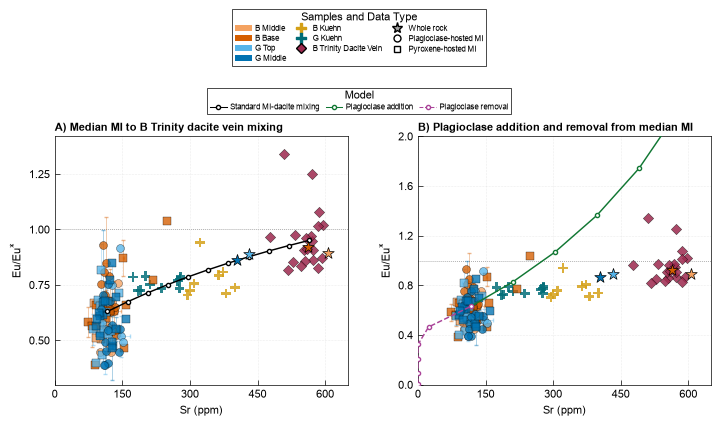

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(DOUBLE_COLUMN_WIDTH_IN, 4.6))

for axis_index, axis in enumerate(axes):
    for tephra in ['B', 'G']:
        group = kuehn.loc[kuehn['Tephra'].eq(tephra)].dropna(subset=['Sr', 'Eu_anomaly'])
        axis.scatter(
            group['Sr'], group['Eu_anomaly'], color=KUEHN_COLORS[tephra],
            alpha=0.84, zorder=2, **KUEHN_PLUS_STYLE,
        )

    group = dacite.dropna(subset=['Sr', 'Eu_anomaly'])
    axis.scatter(
        group['Sr'], group['Eu_anomaly'], marker='D', s=28,
        facecolor=DACITE_COLOR, edgecolor='black', linewidth=MINIMUM_LINE_WIDTH_PT,
        alpha=0.86, zorder=3,
    )

    for sample_key in SAMPLE_ORDER:
        for phase_key in PHASE_ORDER:
            group = mi.loc[
                mi['sample_key'].eq(sample_key) & mi['phase_key'].eq(phase_key)
            ].dropna(subset=['Sr', 'Eu_anomaly'])
            axis.errorbar(
                group['Sr'], group['Eu_anomaly'],
                xerr=group['Sr_std_1sigma'], yerr=group['Eu_anomaly_std_1sigma'],
                fmt='none', ecolor=SAMPLE_COLORS[sample_key],
                elinewidth=0.5, capsize=1.5, alpha=0.45, zorder=2,
            )
            axis.scatter(
                group['Sr'], group['Eu_anomaly'], marker=PHASE_MARKERS[phase_key],
                s=(6.0 - MINIMUM_LINE_WIDTH_PT) ** 2,
                facecolor=SAMPLE_COLORS[sample_key], edgecolor='black',
                linewidth=MINIMUM_LINE_WIDTH_PT, alpha=0.78, zorder=3,
            )

    if axis_index == 1:
        for sample_key in SAMPLE_ORDER:
            group = plag_hosts.loc[plag_hosts['sample_key'].eq(sample_key)].dropna(
                subset=['Sr', 'Eu_anomaly']
            )
            axis.scatter(
                group['Sr'], group['Eu_anomaly'], marker='o',
                s=(6.0 - MINIMUM_LINE_WIDTH_PT) ** 2, facecolor='none',
                edgecolor=SAMPLE_COLORS[sample_key], linewidth=0.6, alpha=0.55, zorder=2,
            )

    for sample_key in SAMPLE_ORDER:
        group = whole_rock.loc[whole_rock['sample_key'].eq(sample_key)].dropna(
            subset=['Sr', 'Eu_anomaly']
        )
        axis.scatter(
            group['Sr'], group['Eu_anomaly'], marker='*', s=75,
            facecolor=SAMPLE_COLORS[sample_key], edgecolor='black', linewidth=0.5, zorder=10,
        )

    axis.axhline(1.0, color='0.50', linestyle=':', linewidth=0.55, zorder=0)
    axis.set_xlim(0, 650)
    axis.set_xlabel('Sr (ppm)')
    axis.set_ylabel('Eu/Eu$^{*}$')
    axis.grid(True, linestyle=':', linewidth=0.4, color='0.79', alpha=0.65)
    axis.set_axisbelow(True)
    axis.xaxis.set_major_locator(MaxNLocator(nbins=5))
    axis.yaxis.set_major_locator(MaxNLocator(nbins=5))
    for spine in axis.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.5)

axes[0].plot(
    mi_dacite_model['Sr'], mi_dacite_model['Eu_anomaly'], color='black',
    linewidth=1.05, marker='o', markersize=3.0, markerfacecolor='white',
    markeredgecolor='black', zorder=6,
)
axes[1].plot(
    plag_addition_model['Sr'], plag_addition_model['Eu_anomaly'], color='#117733',
    linewidth=1.05, marker='o', markersize=3.0, markerfacecolor='white',
    markeredgecolor='#117733', zorder=6,
)
axes[1].plot(
    plag_removal_model['Sr'], plag_removal_model['Eu_anomaly'], color='#AA4499',
    linewidth=1.05, linestyle='--', marker='o', markersize=3.0,
    markerfacecolor='white', markeredgecolor='#AA4499', zorder=6,
)

axes[0].set_ylim(0.3, 1.42)
axes[1].set_ylim(0.0, 2.0)
axes[0].set_title('A) Median MI to B Trinity dacite vein mixing', loc='left', fontsize=BASE_TEXT_SIZE_PT, fontweight='bold', pad=4)
axes[1].set_title('B) Plagioclase addition and removal from median MI', loc='left', fontsize=BASE_TEXT_SIZE_PT, fontweight='bold', pad=4)

sample_handles = [Patch(facecolor=SAMPLE_COLORS[key], edgecolor='none', label=SAMPLE_LABELS[key]) for key in SAMPLE_ORDER]
observation_handles = [
    Line2D([], [], marker=KUEHN_PLUS_PATH, linestyle='none', color=KUEHN_COLORS['B'], markersize=MARKER_SPAN_PT, label='B Kuehn'),
    Line2D([], [], marker=KUEHN_PLUS_PATH, linestyle='none', color=KUEHN_COLORS['G'], markersize=MARKER_SPAN_PT, label='G Kuehn'),
    Line2D([], [], marker='D', linestyle='none', markerfacecolor=DACITE_COLOR, markeredgecolor='black', markersize=5, label='B Trinity Dacite Vein'),
    Line2D([], [], marker='*', linestyle='none', markerfacecolor='0.65', markeredgecolor='black', markersize=8, label='Whole rock'),
]
host_handles = [
    Line2D([], [], marker='o', linestyle='none', markerfacecolor='white', markeredgecolor='black', markersize=5, label=PHASE_LABELS['plag']),
    Line2D([], [], marker='s', linestyle='none', markerfacecolor='white', markeredgecolor='black', markersize=5, label=PHASE_LABELS['pxy']),
]
model_handles = [
    Line2D([], [], color='black', marker='o', markerfacecolor='white', markersize=3, label='Standard MI-dacite mixing'),
    Line2D([], [], color='#117733', marker='o', markerfacecolor='white', markersize=3, label='Plagioclase addition'),
    Line2D([], [], color='#AA4499', linestyle='--', marker='o', markerfacecolor='white', markersize=3, label='Plagioclase removal'),
]
samples_legend = figure.legend(handles=sample_handles + observation_handles + host_handles, title='Samples and Data Type', loc='upper center', bbox_to_anchor=(0.5, 0.965), ncol=3, frameon=True, fancybox=False, facecolor='white', edgecolor='black', framealpha=1.0, fontsize=6.0, title_fontsize=BASE_TEXT_SIZE_PT, handletextpad=0.4, labelspacing=0.25, columnspacing=0.8, borderpad=0.35)
samples_legend.get_frame().set_linewidth(0.5)
model_legend = figure.legend(handles=model_handles, title='Model', loc='upper center', bbox_to_anchor=(0.5, 0.795), ncol=3, frameon=True, fancybox=False, facecolor='white', edgecolor='black', framealpha=1.0, fontsize=6.0, title_fontsize=BASE_TEXT_SIZE_PT, handletextpad=0.4, labelspacing=0.25, columnspacing=0.8, borderpad=0.35)
model_legend.get_frame().set_linewidth(0.5)
figure.subplots_adjust(left=0.08, right=0.985, bottom=0.14, top=0.68, wspace=0.24)

output_stem = OUTPUT_DIRECTORY / 'Figure_S21_Eu_Anomaly_vs_Sr'
figure.savefig(output_stem.with_suffix('.pdf'), format='pdf', dpi=EXPORT_DPI)
figure.savefig(output_stem.with_suffix('.png'), format='png', dpi=EXPORT_DPI)
figure.savefig(output_stem.with_suffix('.svg'), format='svg', dpi=EXPORT_DPI)
plt.show()

## 6. Short output check

In [6]:
if PROJECT_ROOT is None or len(mi) == 0 or len(dacite) == 0 or len(whole_rock) != 4:
    raise ValueError('The established Figure S21 source populations changed.')
if not (OUTPUT_DIRECTORY / 'Figure_S21_Eu_Anomaly_vs_Sr.png').is_file():
    raise FileNotFoundError('Figure S21 PNG export is missing.')
with Image.open(OUTPUT_DIRECTORY / 'Figure_S21_Eu_Anomaly_vs_Sr.png') as image:
    print(f'Final PNG dimensions: {image.size}')
print('Figure S21 output check passed.')

Final PNG dimensions: (2175, 1380)
Figure S21 output check passed.
